# Deep Learning Project 1: ResNet on CIFAR-10 (under 5M parameters)

Run the cells from top to bottom.

1. **First run:** keep `EPOCHS = 30` to check everything works and make a first Kaggle submission.
2. **Real run:** set `EPOCHS = 200`, change `RUN_NAME`, and run again.
3. **Final run:** set `VAL_SIZE = 0` to train on all 50,000 images.

Checkpoints are saved to Google Drive, so if Colab disconnects, just run all cells again and training continues where it stopped.

## 1. Connect Drive and unzip the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/dl_project1'   # checkpoints and results go here
os.makedirs(PROJECT_DIR, exist_ok=True)

if not os.path.exists('/content/data'):
    os.system('cp /content/drive/MyDrive/data.zip /content/')
    os.system('unzip -q /content/data.zip -d /content/data')
    print('Data unzipped.')
else:
    print('Data already there.')

!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Data unzipped.
name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


## 2. Settings

In [ ]:
import glob, time, math, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

SEED = 42
EPOCHS = 200            # 30 for a quick test run, 200 for the real run
BATCH_SIZE = 128
LR = 0.1               # peak learning rate
WEIGHT_DECAY = 5e-4
LABEL_SMOOTHING = 0.1
VAL_SIZE = 0           # images held out for validation; set to 0 for the final run
RUN_NAME = 'A_full_e200'   # change this for every new experiment

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = True
device = 'cuda'
print('PyTorch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))

PyTorch 2.11.0+cu130 | GPU: NVIDIA A100-SXM4-80GB


## 3. Look at the files

In [ ]:
def find_one(pattern):
    hits = glob.glob('/content/data/**/' + pattern, recursive=True)
    assert hits, f'Could not find {pattern} inside /content/data'
    return hits[0]

TRAIN_DIR = find_one('train_images')
TEST_DIR = find_one('test_images')
train_df = pd.read_csv(find_one('train_labels.csv'))
test_df = pd.read_csv(find_one('test.csv'))
sample_df = pd.read_csv(find_one('sample_submission.csv'))

print('train_labels.csv:', train_df.shape); print(train_df.head(3), '\n')
print('test.csv:', test_df.shape); print(test_df.head(3), '\n')
print('sample_submission.csv:', sample_df.shape); print(sample_df.head(3), '\n')
print('Some train files:', sorted(os.listdir(TRAIN_DIR))[:5])
print('Some test files:', sorted(os.listdir(TEST_DIR))[:5])

train_labels.csv: (50000, 3)
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9 

test.csv: (2000, 2)
   id       filename
0   0  test_0000.png
1   1  test_0001.png
2   2  test_0002.png 

sample_submission.csv: (2000, 2)
   id  label
0   0      0
1   1      0
2   2      0 

Some train files: ['train_00000.png', 'train_00001.png', 'train_00002.png', 'train_00003.png', 'train_00004.png']
Some test files: ['test_0000.png', 'test_0001.png', 'test_0002.png', 'test_0003.png', 'test_0004.png']


## 4. Load all images into memory (saved to Drive after the first time)

In [ ]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

def id_column(df):
    if 'id' in df.columns:
        return 'id'
    return [c for c in df.columns if 'id' in c.lower()][0]

def image_paths(df, folder):
    # use a column of .png file names if there is one, otherwise build "<id>.png"
    for c in df.columns:
        s = df[c].astype(str)
        if s.str.lower().str.endswith('.png').all():
            return [os.path.join(folder, os.path.basename(v)) for v in s]
    return [os.path.join(folder, f'{v}.png') for v in df[id_column(df)]]

def labels_of(df):
    col = [c for c in df.columns if 'label' in c.lower()][0]
    vals = df[col]
    if vals.dtype == object:   # class names instead of numbers
        return np.array([CLASSES.index(str(v).strip().lower()) for v in vals], dtype=np.int64)
    return vals.to_numpy().astype(np.int64)

def load_images(paths):
    def read(p):
        return np.array(Image.open(p).convert('RGB'))
    with ThreadPoolExecutor(16) as ex:
        return np.stack(list(ex.map(read, paths)))

cache = os.path.join(PROJECT_DIR, 'data_cache.npz')
if os.path.exists(cache):
    d = np.load(cache, allow_pickle=True)
    X_train, y_train, X_test, test_ids = d['X_train'], d['y_train'], d['X_test'], d['test_ids']
    print('Loaded from cache.')
else:
    train_paths = image_paths(train_df, TRAIN_DIR)
    test_paths = image_paths(test_df, TEST_DIR)
    assert os.path.exists(train_paths[0]), f'Missing {train_paths[0]}: check the file names printed above'
    assert os.path.exists(test_paths[0]), f'Missing {test_paths[0]}: check the file names printed above'
    t0 = time.time()
    X_train = load_images(train_paths)
    y_train = labels_of(train_df)
    X_test = load_images(test_paths)
    test_ids = test_df[id_column(test_df)].astype(str).to_numpy()
    np.savez(cache, X_train=X_train, y_train=y_train, X_test=X_test, test_ids=test_ids)
    print(f'Loaded images in {time.time() - t0:.0f}s and saved cache.')

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Images per class:', np.bincount(y_train))

Loaded from cache.
Train: (50000, 32, 32, 3) | Test: (2000, 32, 32, 3)
Images per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


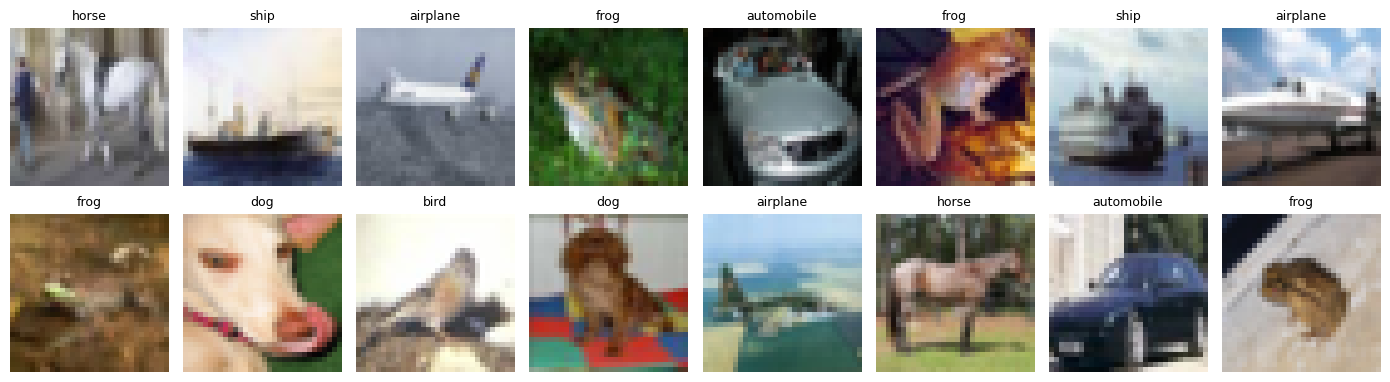

In [ ]:
# quick visual check that images and labels match
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, np.random.choice(len(X_train), 16, replace=False)):
    ax.imshow(X_train[i]); ax.set_title(CLASSES[y_train[i]], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Move data to the GPU, split, and set up augmentation

In [ ]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1)

def to_tensor(x):
    x = torch.from_numpy(x).to(device).permute(0, 3, 1, 2).float() / 255.0
    return (x - MEAN) / STD

perm = np.random.RandomState(SEED).permutation(len(X_train))
val_idx, tr_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

Xtr = to_tensor(X_train[tr_idx]); ytr = torch.from_numpy(y_train[tr_idx]).to(device)
Xval = to_tensor(X_train[val_idx]); yval = torch.from_numpy(y_train[val_idx]).to(device)
Xte = to_tensor(X_test)
print('Train:', len(Xtr), '| Val:', len(Xval), '| Test:', len(Xte))

# augmentation done on the GPU, a whole batch at once (much faster than a DataLoader)
def random_crop(x, pad=4):
    n, c, h, w = x.shape
    xp = F.pad(x, (pad, pad, pad, pad), mode='reflect')
    i = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    rows = (i[:, None] + torch.arange(h, device=x.device)[None])[:, None, :, None]
    cols = (j[:, None] + torch.arange(w, device=x.device)[None])[:, None, None, :]
    n_idx = torch.arange(n, device=x.device)[:, None, None, None]
    c_idx = torch.arange(c, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows, cols]

def random_flip(x):
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def cutout(x, size=16):
    n, _, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1, 1), device=x.device)
    ys = torch.arange(h, device=x.device)[None, :, None]
    xs = torch.arange(w, device=x.device)[None, None, :]
    hole = ((ys - cy).abs() < size // 2) & ((xs - cx).abs() < size // 2)
    return x * (~hole)[:, None].float()

def color_jitter(x, strength=0.3):
    n = x.shape[0]
    img = x * STD + MEAN
    def rnd():
        return 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * strength
    img = img * rnd()
    m = img.mean(dim=(1, 2, 3), keepdim=True)
    img = (img - m) * rnd() + m
    gray = 0.299 * img[:, 0:1] + 0.587 * img[:, 1:2] + 0.114 * img[:, 2:3]
    img = (img - gray) * rnd() + gray
    return (img.clamp(0, 1) - MEAN) / STD

def random_zoom(x, min_scale=0.75, max_shift=0.25):
    n = x.shape[0]
    s = torch.empty(n, device=x.device).uniform_(min_scale, 1.0)
    theta = torch.zeros(n, 2, 3, device=x.device)
    theta[:, 0, 0] = s
    theta[:, 1, 1] = s
    theta[:, 0, 2] = (torch.rand(n, device=x.device) * 2 - 1) * max_shift
    theta[:, 1, 2] = (torch.rand(n, device=x.device) * 2 - 1) * max_shift
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

def augment(x):
    return cutout(random_flip(random_crop(x)))   # Run A setup (Run B used color_jitter + random_zoom)

Train: 50000 | Val: 0 | Test: 2000


## 6. Model

A 3-stage ResNet. Each stage has 3 residual blocks (conv, BN, ReLU, conv, BN, plus skip connection).
Channels are 64, 128, 256. Stages 2 and 3 halve the image size with stride 2.
Skip connections are identity, or a 1x1 conv when the shape changes.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1, k=3):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, k, stride, k // 2, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, k, 1, k // 2, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Sequential()
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride, bias=False),
                nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))   # ReLU(F(x) + S(x))


class ResNet(nn.Module):
    def __init__(self, channels=(64, 128, 256), blocks=(3, 3, 3), num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels[0]),
            nn.ReLU(inplace=True))
        layers, c_in = [], channels[0]
        for i, (c, b) in enumerate(zip(channels, blocks)):
            stride = 1 if i == 0 else 2
            for j in range(b):
                layers.append(BasicBlock(c_in, c, stride if j == 0 else 1))
                c_in = c
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(channels[-1], num_classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)   # global average pool
        return self.fc(x)


model = ResNet().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')
assert n_params <= 5_000_000, 'Model is over the 5M parameter limit!'

Trainable parameters: 4,327,754


In [ ]:
# full layer-by-layer summary (the project PDF suggests torchsummary)
!pip install -q torchsummary
from torchsummary import summary
summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,864
       BatchNorm2d-5           [-1, 64, 32, 32]             128
            Conv2d-6           [-1, 64, 32, 32]          36,864
       BatchNorm2d-7           [-1, 64, 32, 32]             128
        BasicBlock-8           [-1, 64, 32, 32]               0
            Conv2d-9           [-1, 64, 32, 32]          36,864
      BatchNorm2d-10           [-1, 64, 32, 32]             128
           Conv2d-11           [-1, 64, 32, 32]          36,864
      BatchNorm2d-12           [-1, 64, 32, 32]             128
       BasicBlock-13           [-1, 64, 32, 32]               0
           Conv2d-14           [-1, 64,

## 7. Train

In [ ]:
model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9,
                            nesterov=True, weight_decay=WEIGHT_DECAY)
steps_per_epoch = math.ceil(len(Xtr) / BATCH_SIZE)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=steps_per_epoch, pct_start=0.15)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
scaler = torch.amp.GradScaler('cuda')

@torch.no_grad()
def predict(model, X, tta=False, bs=1000):
    # returns logits; tta=True also looks at the mirrored image and averages
    model.eval()
    outs = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs].contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(xb).float()
            if tta:
                logits = logits + model(xb.flip(3)).float()
        outs.append(logits)
    return torch.cat(outs)

def accuracy(logits, y):
    return (logits.argmax(1) == y).float().mean().item() * 100

ckpt_path = os.path.join(PROJECT_DIR, f'{RUN_NAME}_last.pt')
start_epoch, history = 0, []
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, weights_only=False)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    start_epoch, history = ck['epoch'], ck['history']
    print(f'Resuming from epoch {start_epoch}')

def save_checkpoint(epoch):
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                'epoch': epoch, 'history': history}, ckpt_path)

for epoch in range(start_epoch, EPOCHS):
    model.train()
    t0 = time.time()
    order = torch.randperm(len(Xtr), device=device)
    loss_sum, correct = 0.0, 0
    for i in range(0, len(Xtr), BATCH_SIZE):
        b = order[i:i + BATCH_SIZE]
        xb = augment(Xtr[b]).contiguous(memory_format=torch.channels_last)
        yb = ytr[b]
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(xb)
            loss = criterion(out, yb)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item() * len(b)
        correct += (out.argmax(1) == yb).sum().item()

    train_loss = loss_sum / len(Xtr)
    train_acc = correct / len(Xtr) * 100
    if len(Xval) > 0:
        val_logits = predict(model, Xval)
        val_loss = F.cross_entropy(val_logits, yval).item()
        val_acc = accuracy(val_logits, yval)
    else:
        val_loss, val_acc = float('nan'), float('nan')
    history.append(dict(epoch=epoch + 1, train_loss=train_loss, train_acc=train_acc,
                        val_loss=val_loss, val_acc=val_acc))
    print(f'Epoch {epoch + 1:3d}/{EPOCHS} | train loss {train_loss:.3f} acc {train_acc:.2f}% '
          f'| val loss {val_loss:.3f} acc {val_acc:.2f}% | {time.time() - t0:.0f}s')

    if (epoch + 1) % 5 == 0 or epoch + 1 == EPOCHS:
        save_checkpoint(epoch + 1)

torch.save(model.state_dict(), os.path.join(PROJECT_DIR, f'{RUN_NAME}_final_weights.pt'))
pd.DataFrame(history).to_csv(os.path.join(PROJECT_DIR, f'{RUN_NAME}_history.csv'), index=False)
print('Training done.')

Epoch   1/200 | train loss 1.616 acc 48.58% | val loss nan acc nan% | 15s
Epoch   2/200 | train loss 1.320 acc 63.44% | val loss nan acc nan% | 5s
Epoch   3/200 | train loss 1.209 acc 68.94% | val loss nan acc nan% | 5s
Epoch   4/200 | train loss 1.130 acc 72.71% | val loss nan acc nan% | 5s
Epoch   5/200 | train loss 1.080 acc 74.98% | val loss nan acc nan% | 5s
Epoch   6/200 | train loss 1.040 acc 76.77% | val loss nan acc nan% | 5s
Epoch   7/200 | train loss 1.009 acc 78.25% | val loss nan acc nan% | 5s
Epoch   8/200 | train loss 0.986 acc 79.29% | val loss nan acc nan% | 5s
Epoch   9/200 | train loss 0.965 acc 80.06% | val loss nan acc nan% | 5s
Epoch  10/200 | train loss 0.944 acc 81.02% | val loss nan acc nan% | 5s
Epoch  11/200 | train loss 0.931 acc 81.63% | val loss nan acc nan% | 5s
Epoch  12/200 | train loss 0.917 acc 82.27% | val loss nan acc nan% | 5s
Epoch  13/200 | train loss 0.898 acc 82.87% | val loss nan acc nan% | 5s
Epoch  14/200 | train loss 0.891 acc 83.25% | val 

## 8. Plots and final numbers

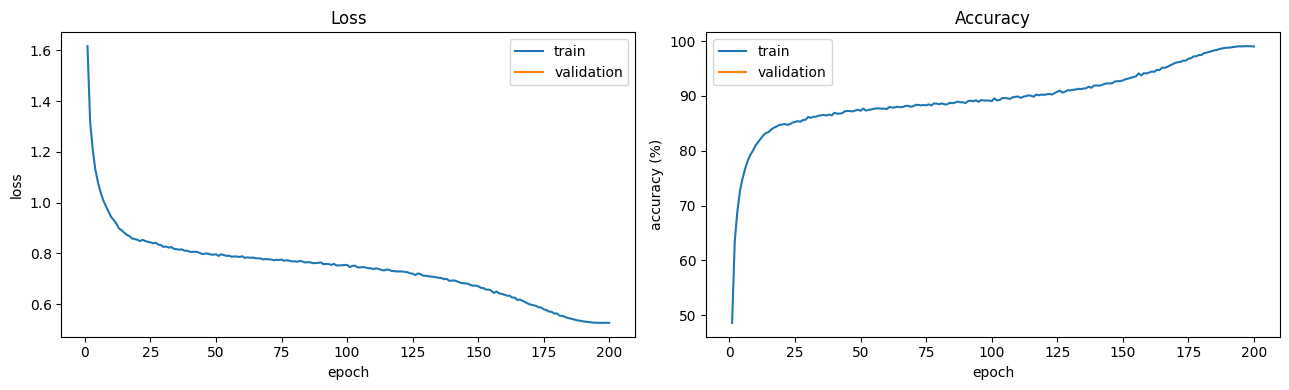

Trainable parameters: 4,327,754


In [ ]:
h = pd.DataFrame(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(h.epoch, h.train_loss, label='train'); ax1.plot(h.epoch, h.val_loss, label='validation')
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.set_title('Loss'); ax1.legend()
ax2.plot(h.epoch, h.train_acc, label='train'); ax2.plot(h.epoch, h.val_acc, label='validation')
ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy (%)'); ax2.set_title('Accuracy'); ax2.legend()
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, f'{RUN_NAME}_curves.png'), dpi=150)
plt.show()

print(f'Trainable parameters: {n_params:,}')
if len(Xval) > 0:
    print(f'Final validation accuracy: {accuracy(predict(model, Xval), yval):.2f}%')
    print(f'Final validation accuracy with flip TTA: {accuracy(predict(model, Xval, tta=True), yval):.2f}%')

## 9. Make submission.csv for Kaggle

In [ ]:
test_preds = predict(model, Xte, tta=True).argmax(1).cpu().numpy()
pred_by_id = dict(zip([str(i) for i in test_ids], test_preds))

sub_id_col = id_column(sample_df)
submission = pd.DataFrame({'id': sample_df[sub_id_col]})   # same order as sample_submission
submission['label'] = sample_df[sub_id_col].astype(str).map(pred_by_id)
assert submission['label'].notna().all(), 'Some test ids have no prediction!'
submission['label'] = submission['label'].astype(int)
assert len(submission) == len(sample_df)

submission.to_csv('submission.csv', index=False)
submission.to_csv(os.path.join(PROJECT_DIR, f'{RUN_NAME}_submission.csv'), index=False)
print(submission.head())
print('Predictions per class:', np.bincount(submission['label'], minlength=10))

from google.colab import files
files.download('submission.csv')

   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
Predictions per class: [172 217 213 199 192 207 186 209 211 194]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>